# What drives groundwater loss? Maps, districts, irrigation and rain

The maps of step 12 show *where* groundwater is being lost; this notebook asks *with what* the loss goes, at the
scale where we have real measurements: 383 Indian districts with at least 5 CGWB wells (2013-2020).
Scripts: `src/12_maps.py` (maps), `src/13_drivers.py` (district analysis). Every number is read from their outputs.

**What hydrology leads us to expect.** In north-west India most irrigation water is pumped from aquifers, and the
dry season (rabi wheat, January-April) is when crops depend on it. Rain recharges aquifers. So the loss should be
fastest where crops are green in the dry season *and* rain is scarce.

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import Image, display
R = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
M = R / "figures/maps"

## 1. Where: the regional picture from GRACE

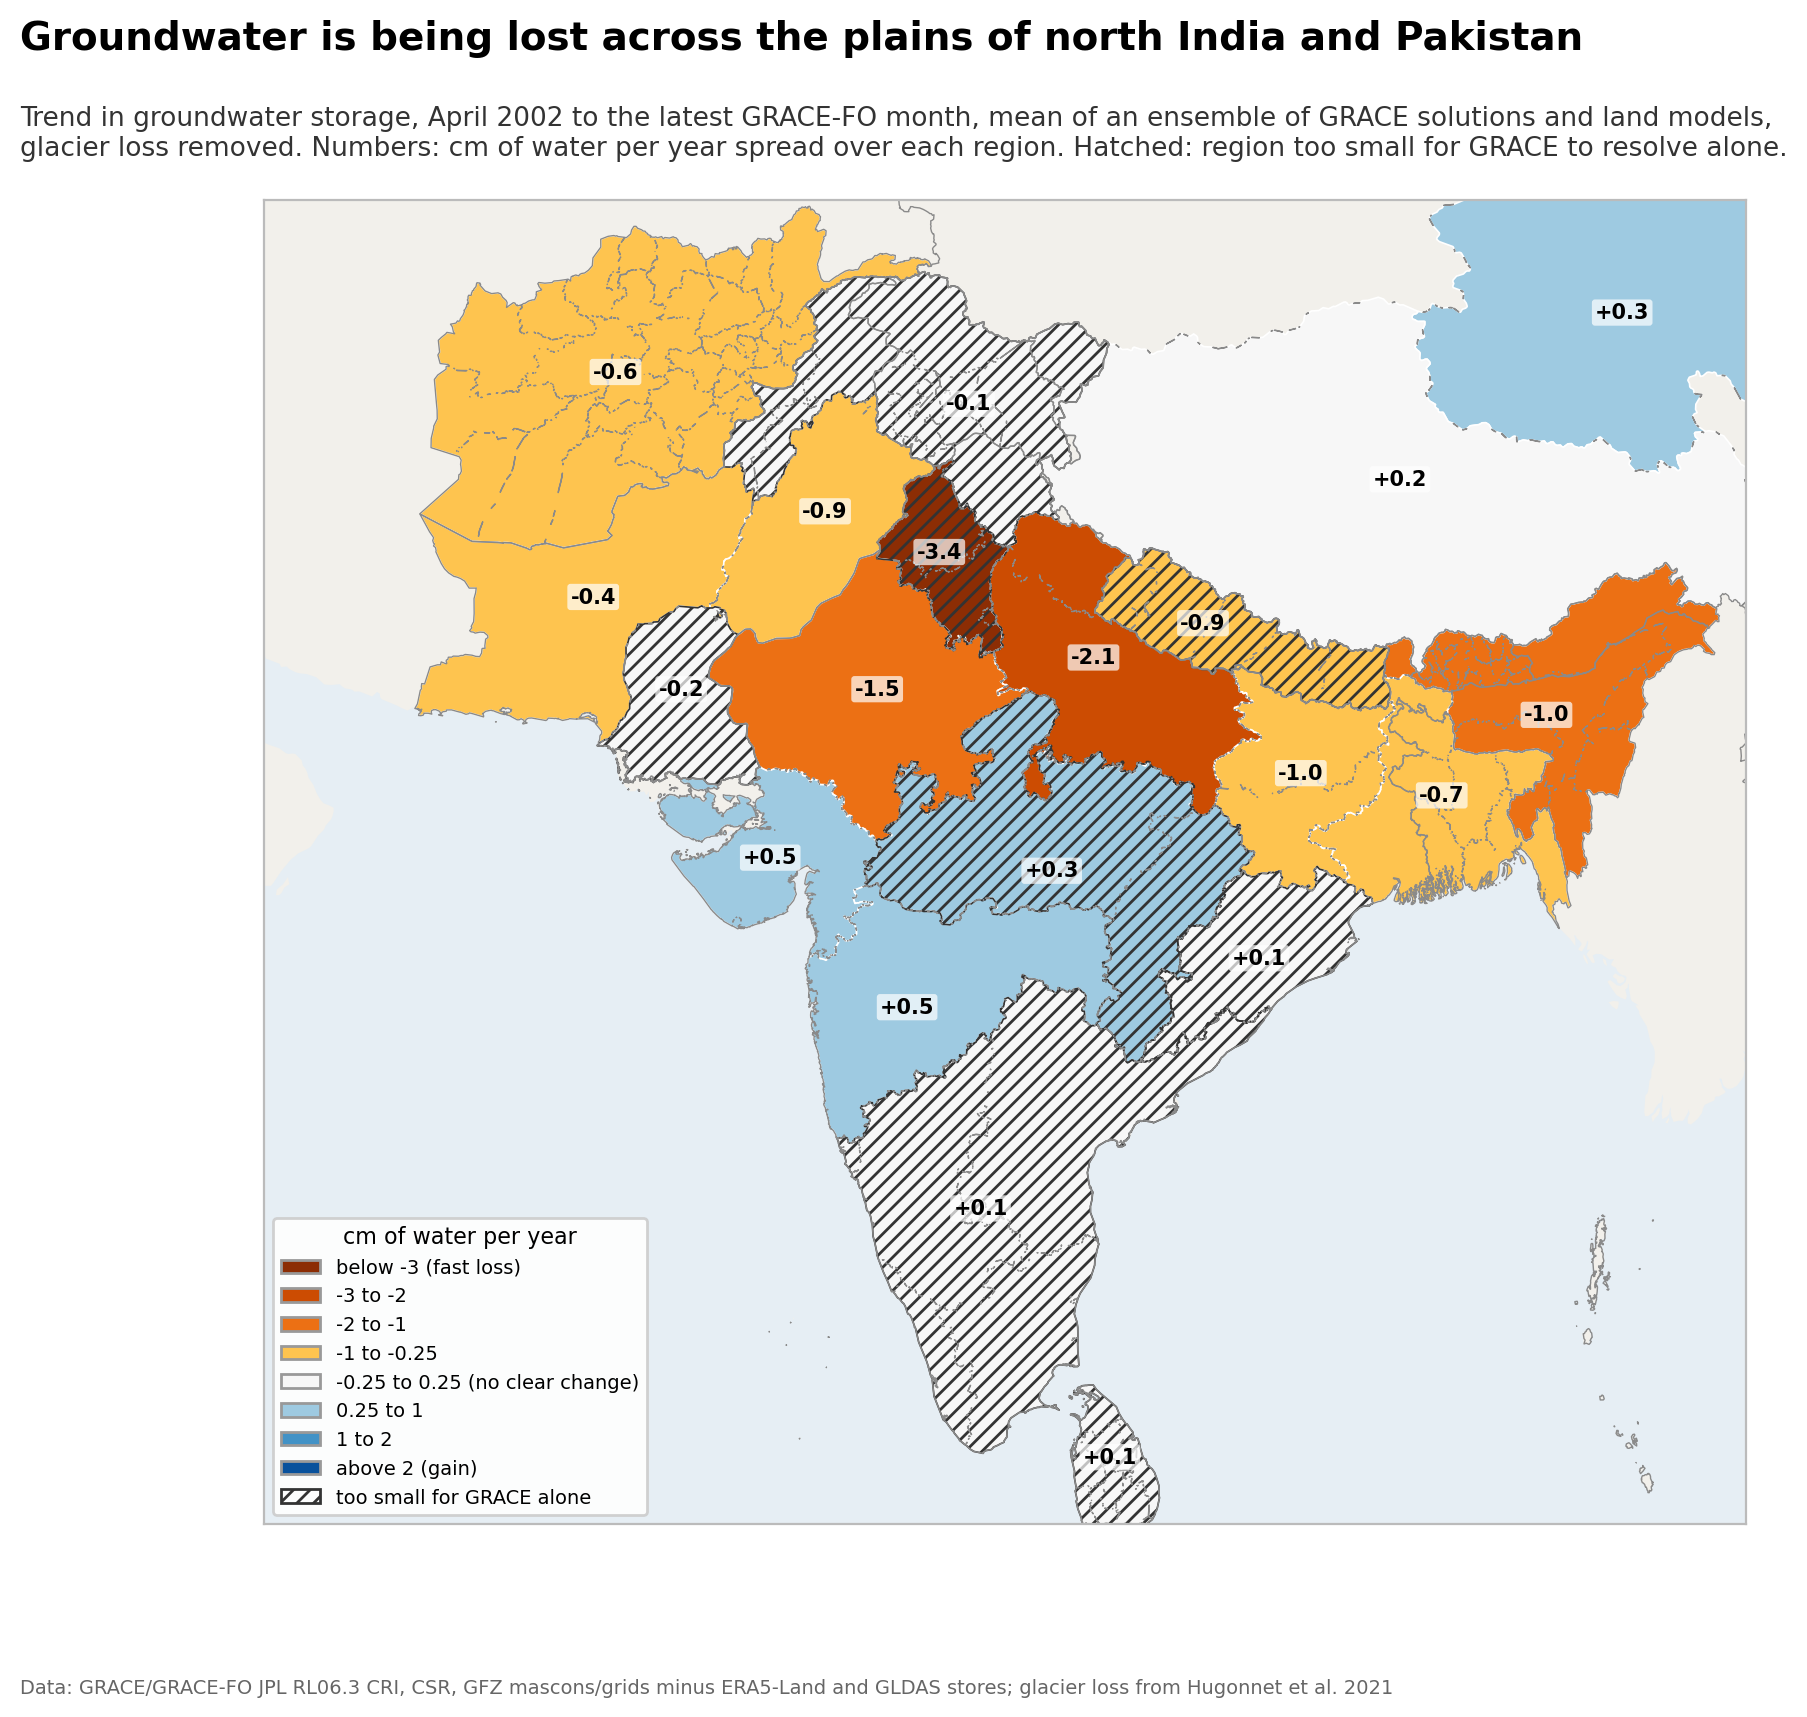

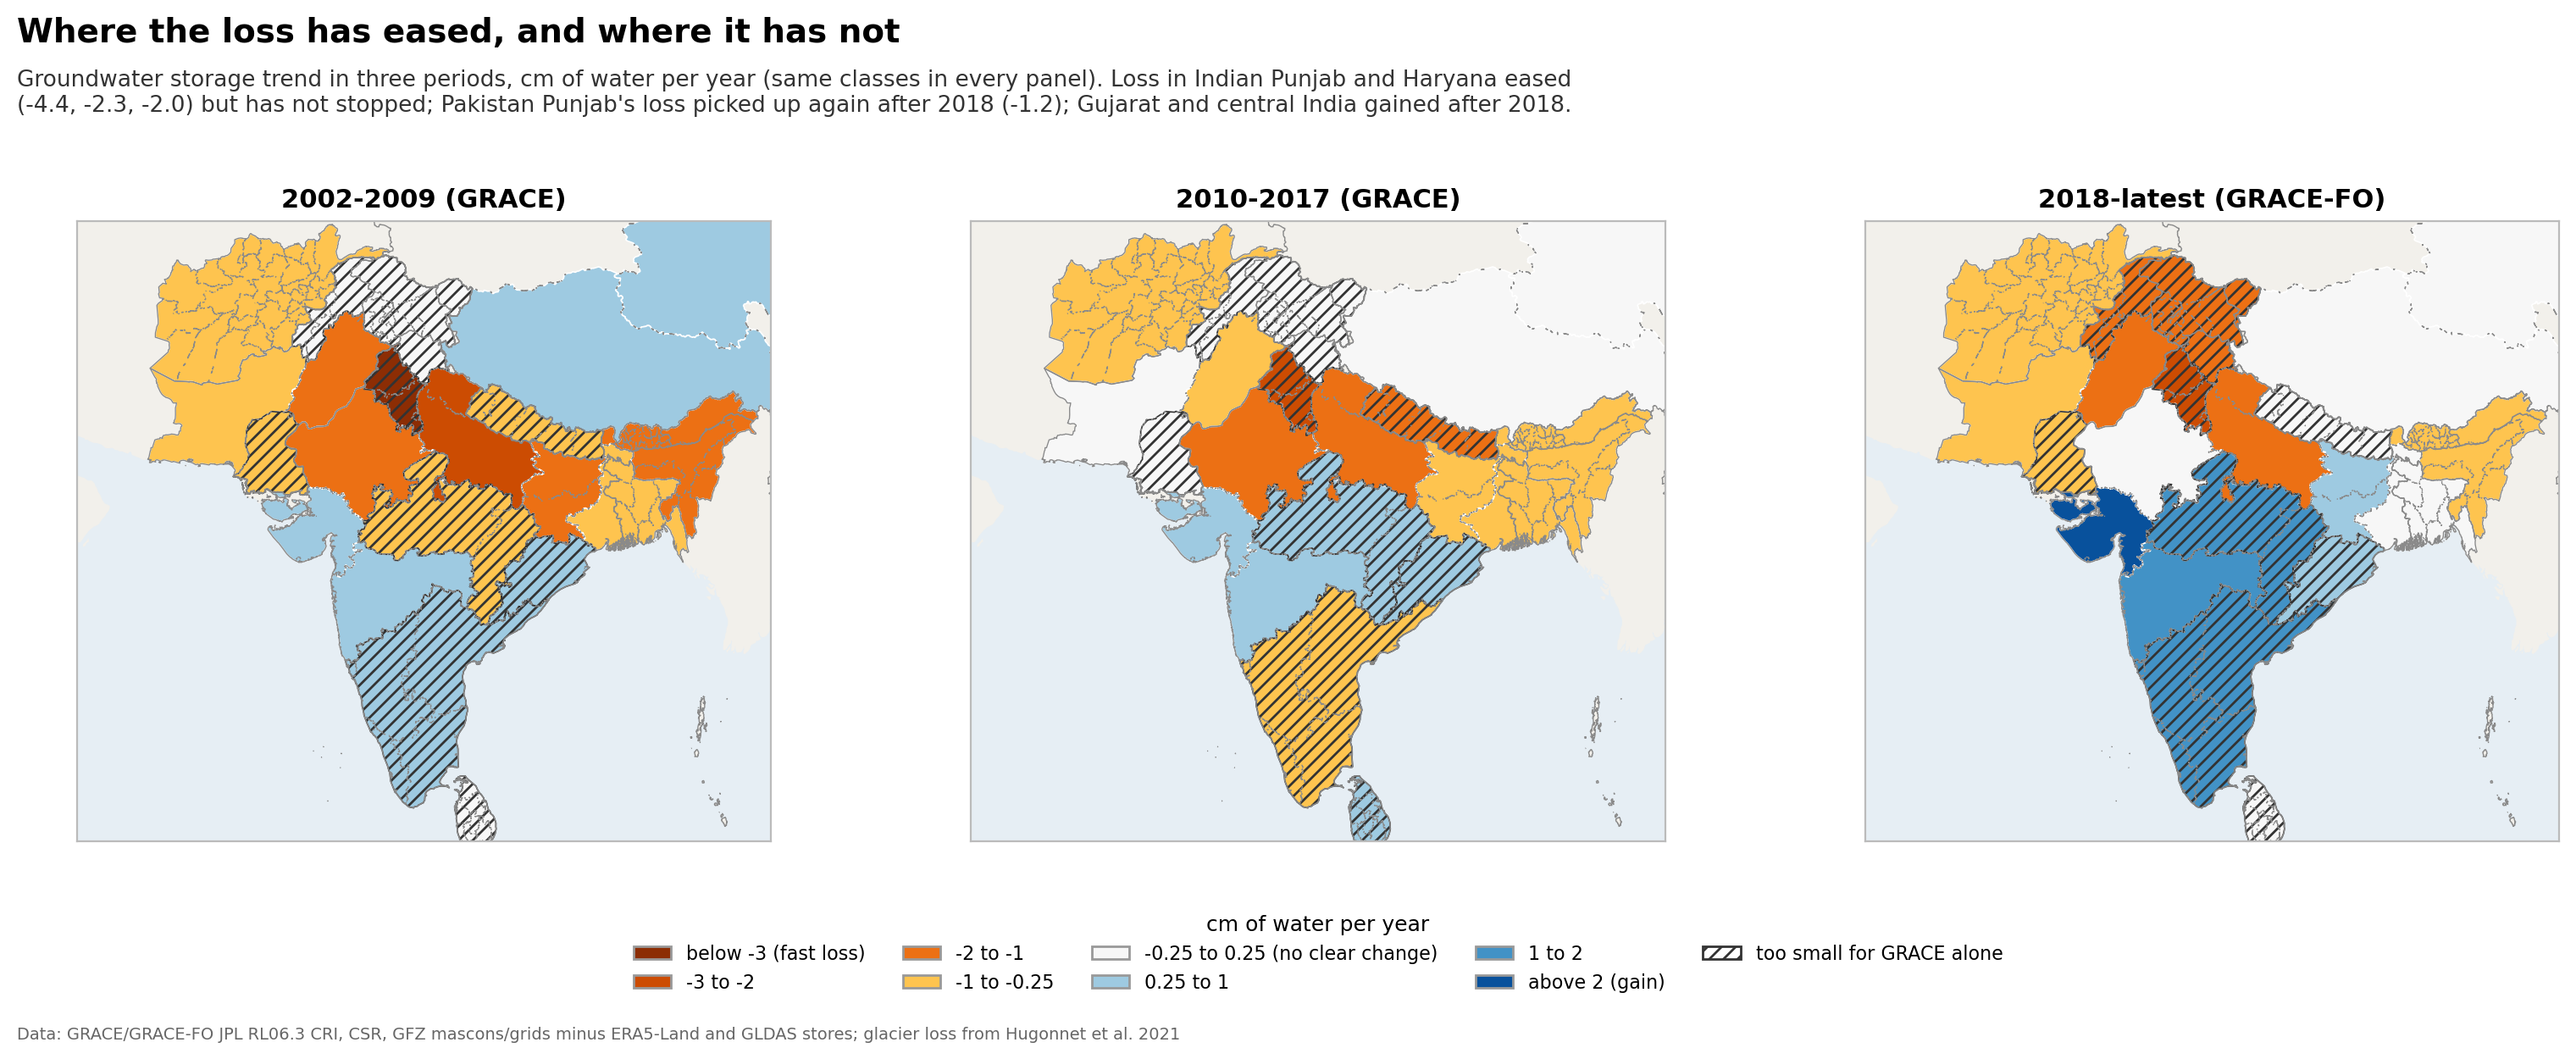

In [2]:
display(Image(M / "01_groundwater_trend_units.png", width=800), Image(M / "02_groundwater_trend_periods.png", width=1000))

## 2. One predictor at a time
Rank correlations between each predictor (averaged over the district) and the district's storage change from wells,
with bootstrap 95% intervals. Negative: more of it, faster loss.

In [3]:
pd.read_csv(R / "outputs/fine/driver_correlations.csv").round(2)

,predictor,spearman_with_storage_change,ci_lo,ci_hi
0,cropland share,-0.41,-0.49,-0.30
1,population density (log10),-0.25,-0.34,-0.16
2,"dry-season greenness (NDVI, Jan-Apr)",-0.15,-0.25,-0.04
3,land temperature Mar-May (C),0.07,-0.03,0.18
4,change in dry-season greenness (per decade),0.13,0.02,0.23
5,rainfall trend (mm/yr per decade),0.15,0.05,0.25
6,rainfall (mm/yr),0.33,0.22,0.43
7,evapotranspiration (mm/yr),0.49,0.40,0.58


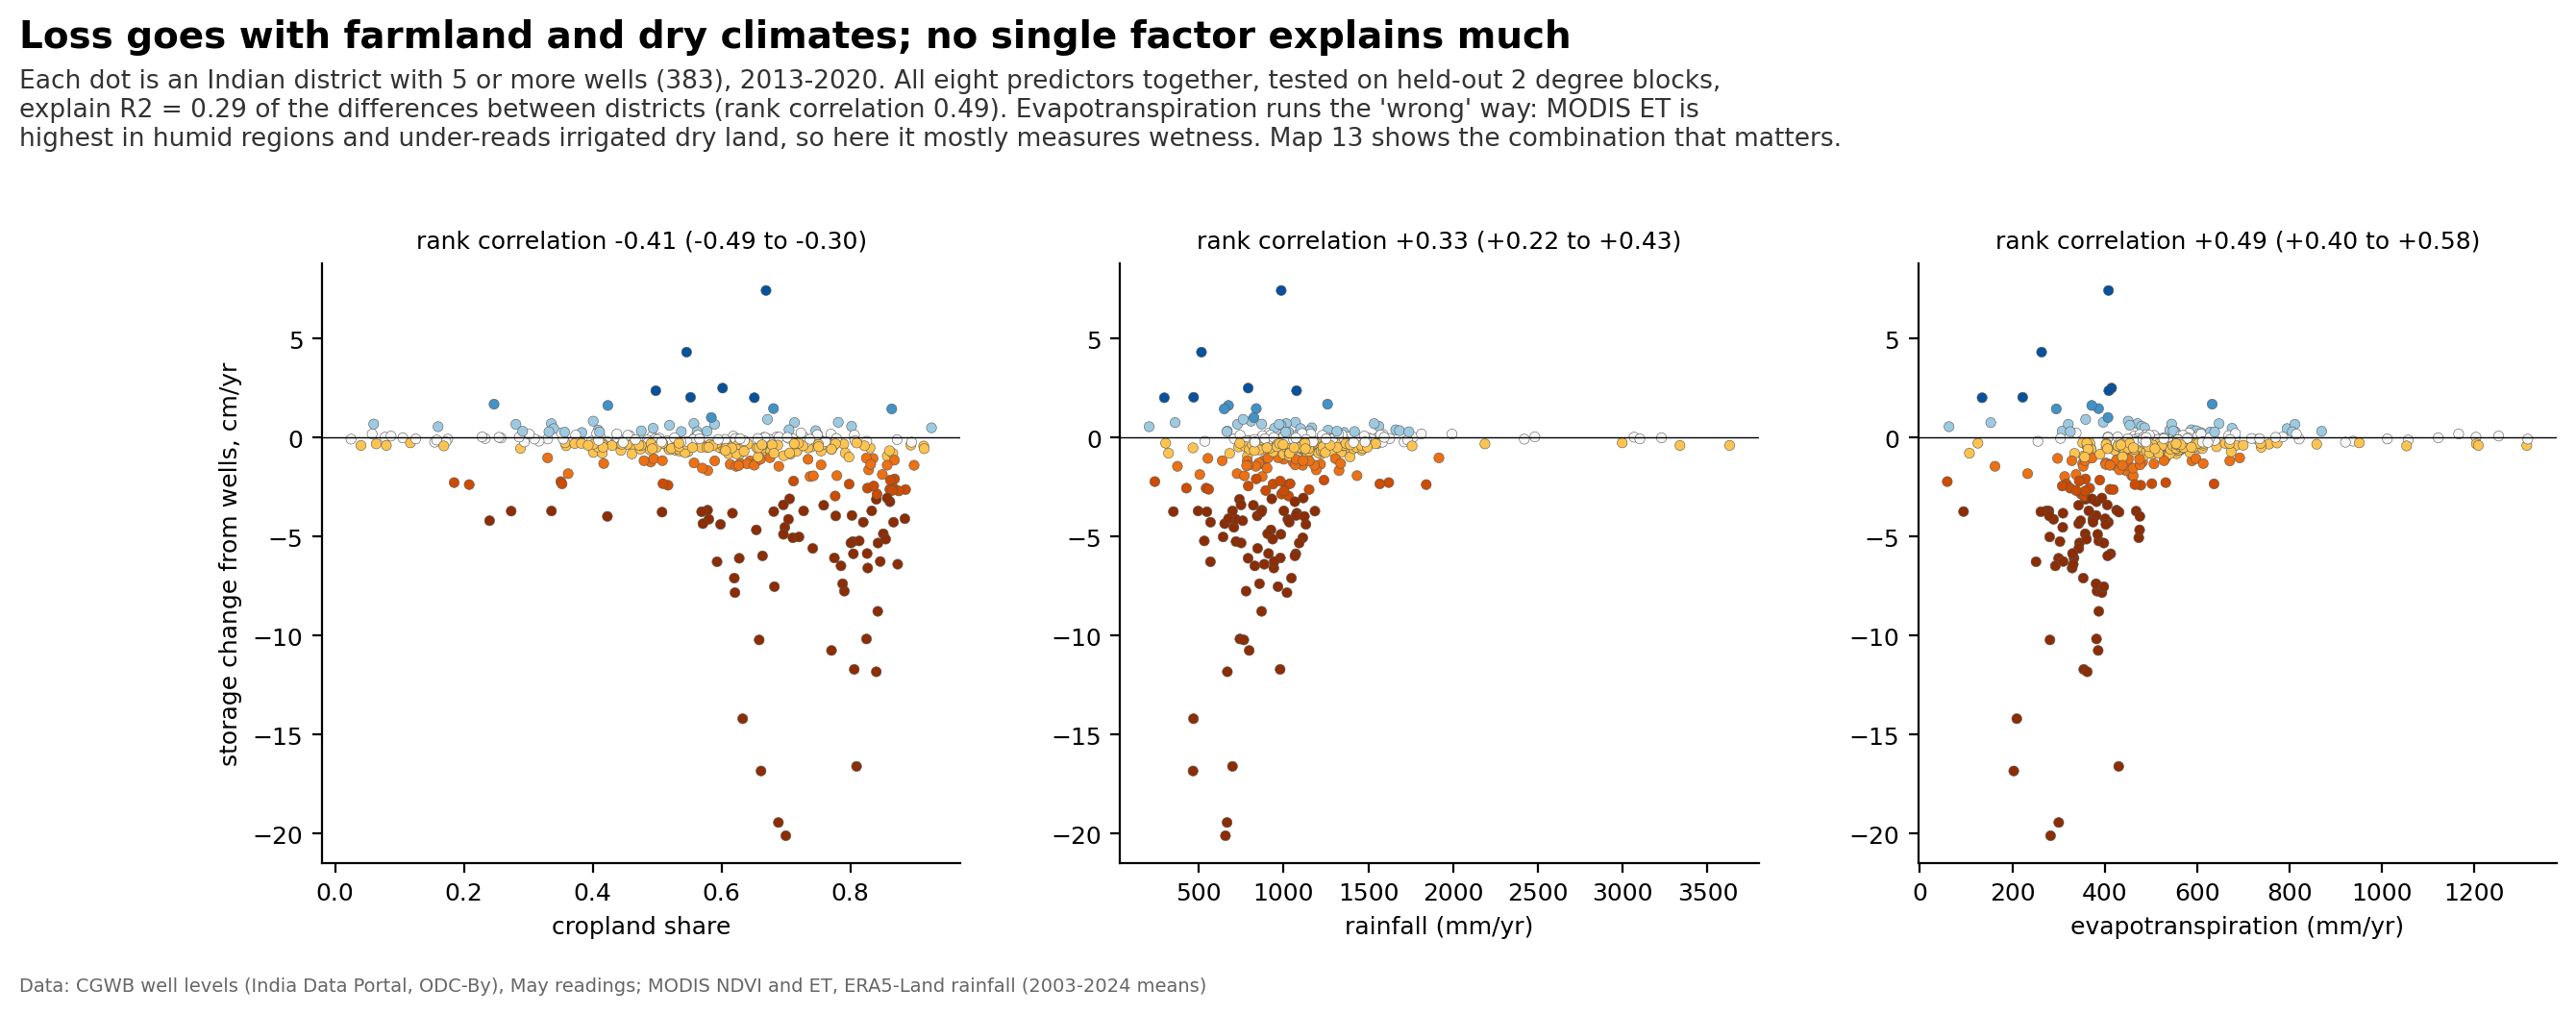

In [4]:
Image(M / "12_drivers_scatter.png", width=1000)

Reading the table with care:
- **Cropland share** goes most clearly with loss: farmland is where water is pumped.
- **More rain, less loss**, as recharge predicts.
- **Evapotranspiration has the "wrong" sign.** MODIS ET is highest in humid regions and is known to under-read
  irrigated fields in dry regions, so across India it mostly measures how wet a place is. A good reminder that a
  satellite product is a model, not a measurement.
- **The rainfall trend** (ERA5-Land) has a weak positive sign: districts getting wetter lose a little less.
  A first run with CHIRPS rainfall gave the opposite sign. CHIRPS roughly doubles Punjab's rainfall in a step in
  2009-2010 (about 375 to 800 mm a year at 75.5 E 30.8 N) that ERA5-Land does not show: a change in the station data
  CHIRPS blends, not in the climate. Always check a trend in a gridded product against a second source.
- **All predictors together** (a random forest tested on held-out regions) explain about a third of the differences
  between districts. The rest is local: aquifer type and depth, canal water, crop choice, electricity for pumps.

## 3. The combination that matters: irrigation without rain

,irrigation,dry,middle,wet
0,low,-0.46,-0.42,-0.38
1,middle,-1.04,-0.51,-0.30
2,high,-3.69,-1.14,-0.20


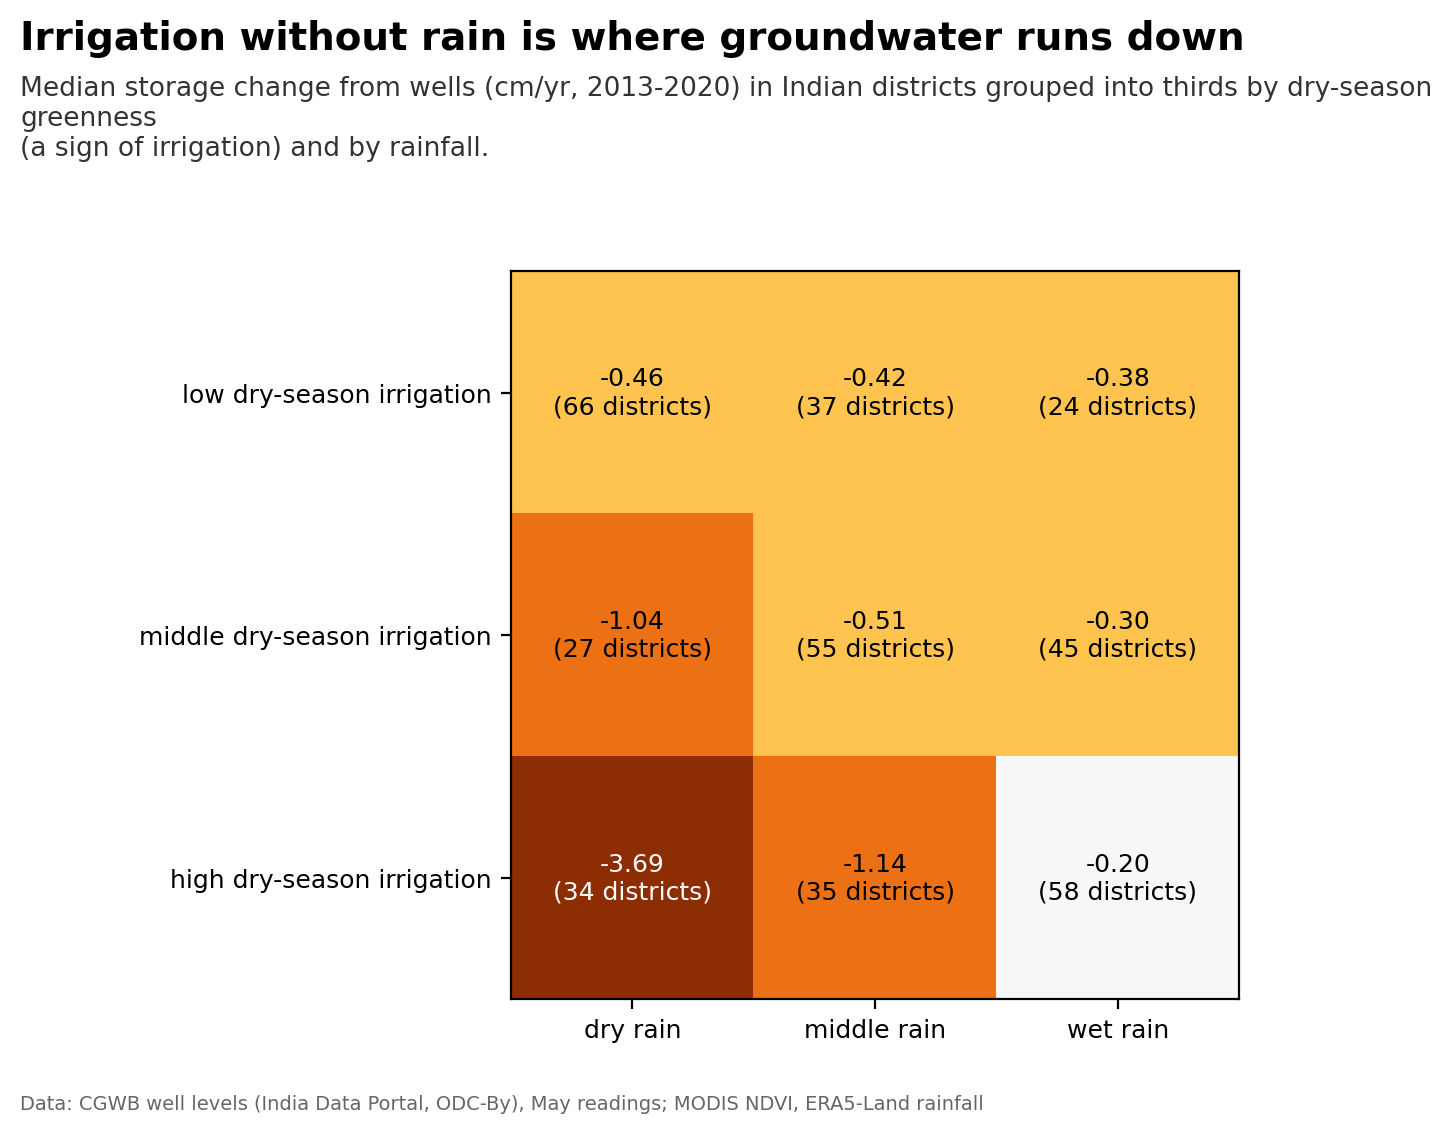

In [5]:
display(pd.read_csv(R / "outputs/fine/irrigation_x_rain.csv").round(2), Image(M / "13_irrigation_x_rain.png", width=650))

Districts in the top third of dry-season greenness and the bottom third of rainfall lose a median of about
3.7 cm of water a year; equally green districts with plenty of rain lose almost nothing. Irrigation alone or dryness
alone does little. That is the signature of pumping exceeding recharge.

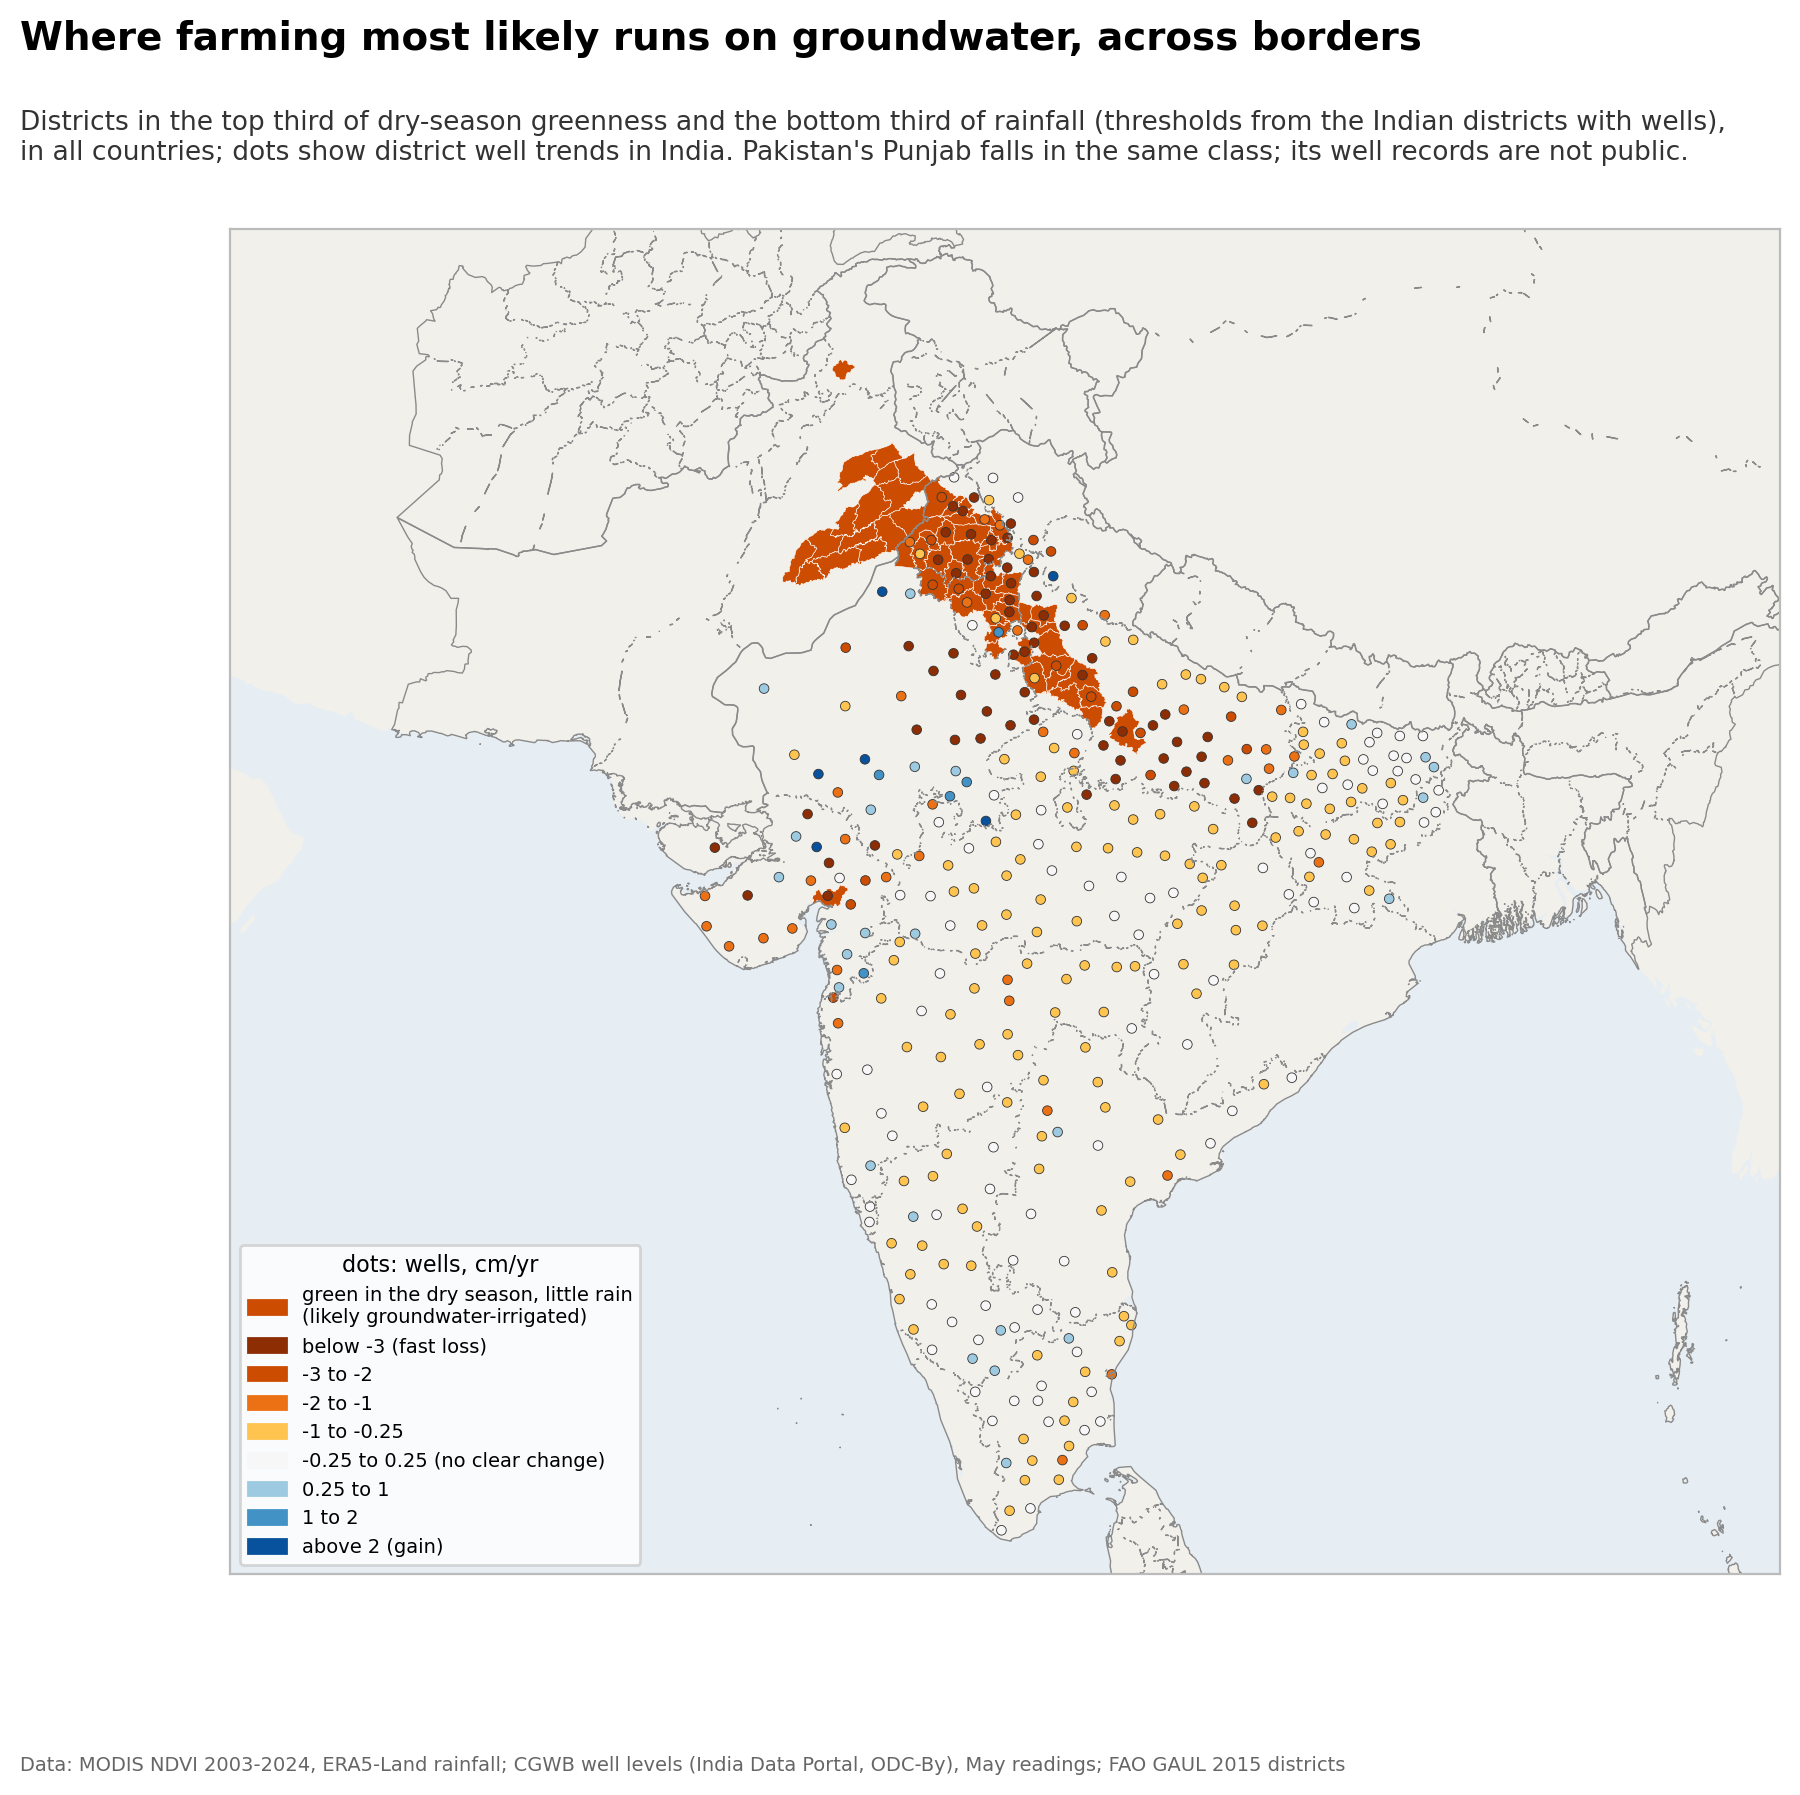

In [6]:
Image(M / "14_groundwater_irrigation_map.png", width=800)

Applying the same thresholds everywhere marks Indian Punjab, Haryana and western Uttar Pradesh, and Pakistan's
Punjab: the same farming on the same aquifer system, across the border. Its well records are not public, which is
why the data requests in `docs/data_requests.md` matter.

## 4. Checking the satellites against the wells

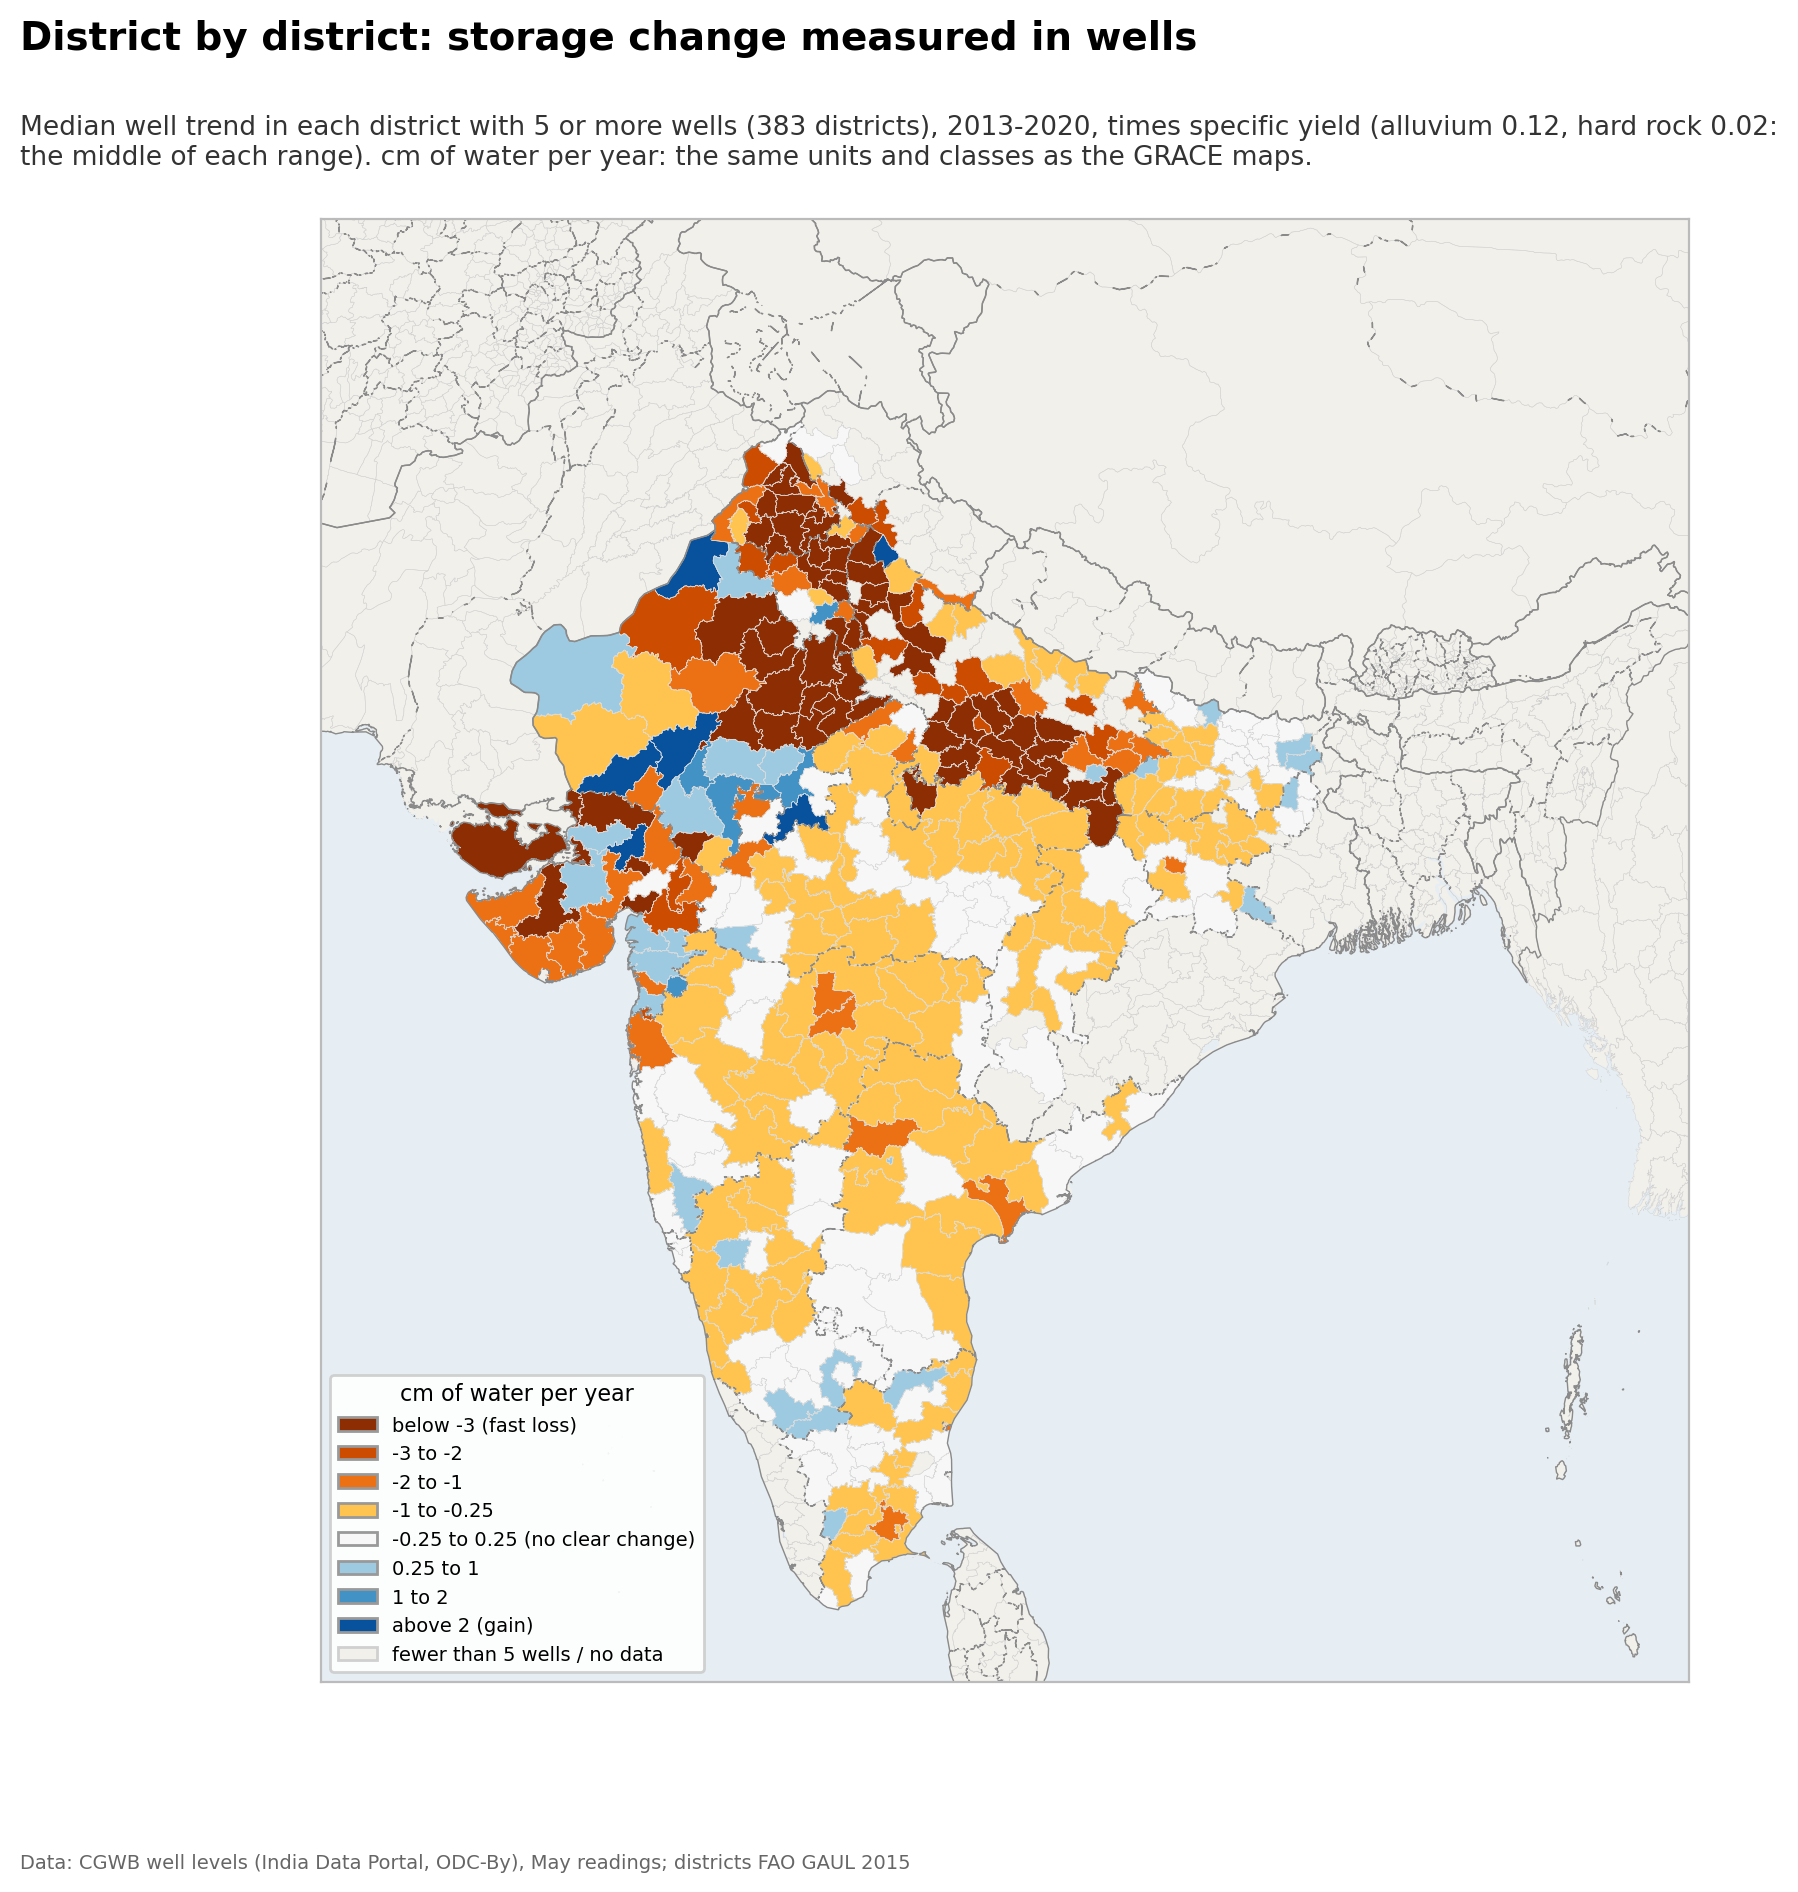

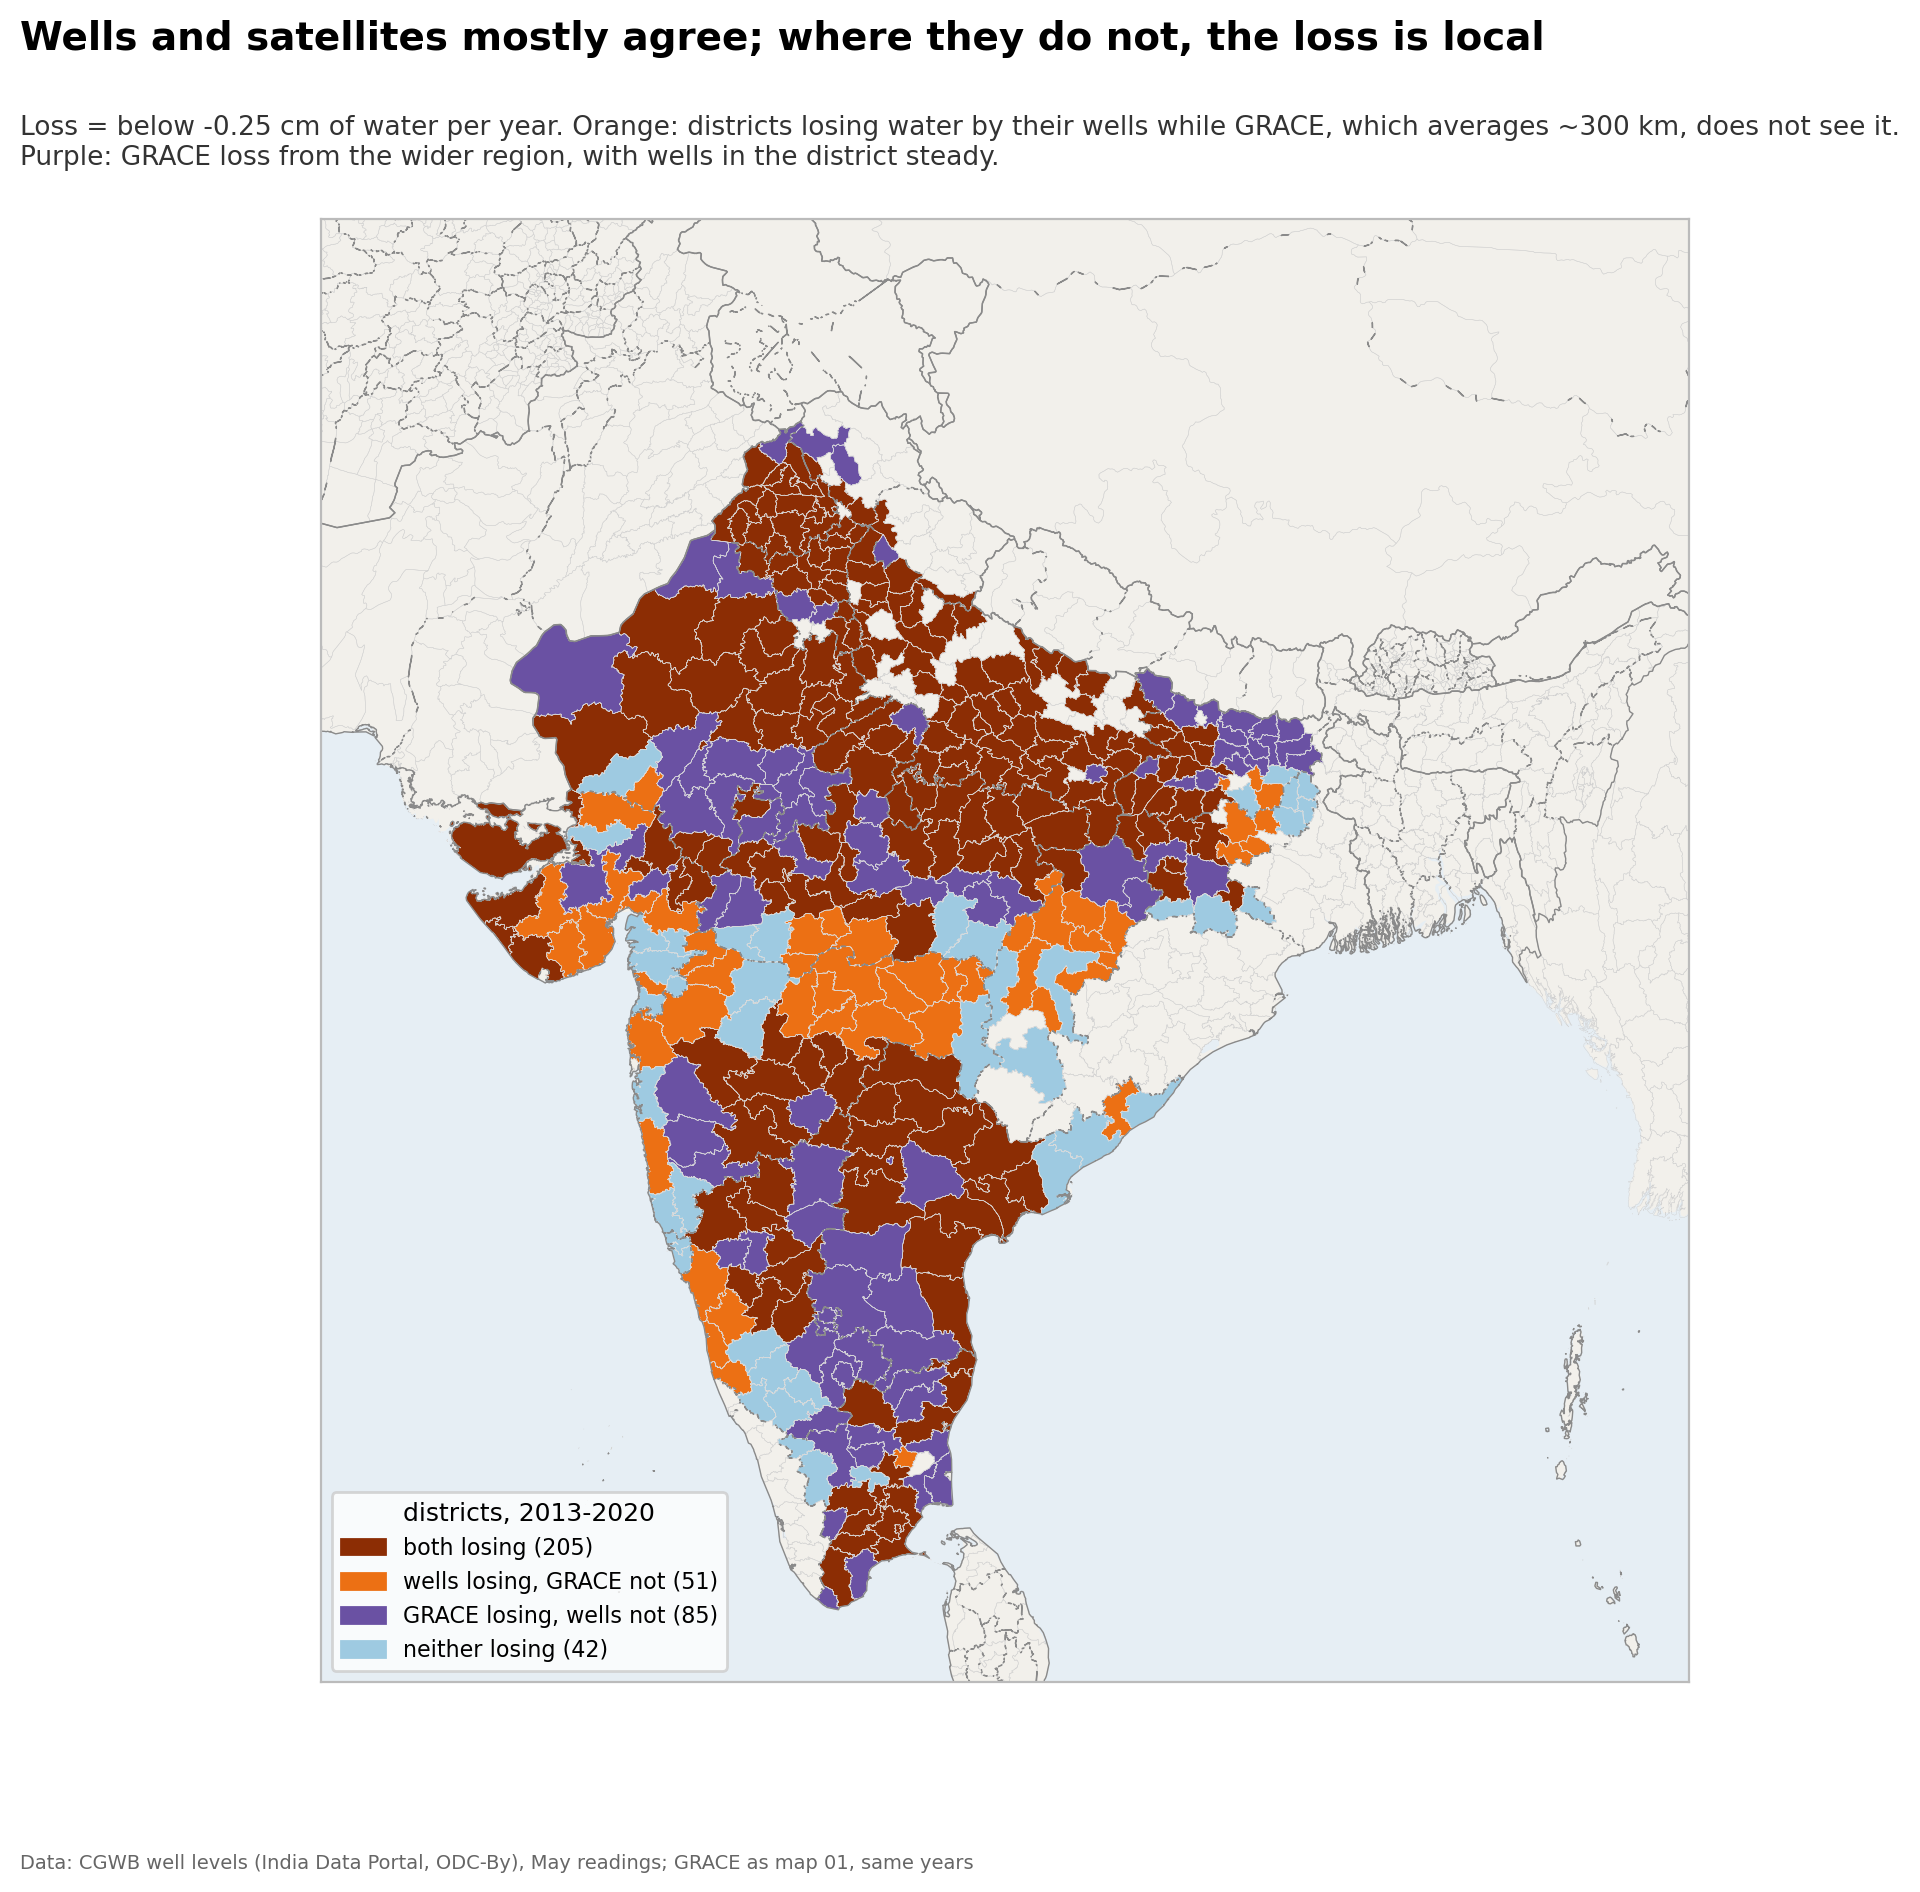

In [7]:
display(Image(M / "05_wells_by_district.png", width=700), Image(M / "06_wells_vs_grace_districts.png", width=700))

## 5. Related work
- `south-asia-smog/notebooks/paddy_law_fires.ipynb`: Punjab's groundwater law (delayed rice transplanting) and
  the move of stubble burning into November.
- `notebooks/fine_scale_groundwater.ipynb`: how far below GRACE's ~300 km we can honestly go.

## 6. A lesson in checking data: CHIRPS rainfall over Punjab
`src/14_chirps_check.py` compares how much rainfall changed between 2003-2008 and 2010-2024 in CHIRPS and in
ERA5-Land, cell by cell. Where only CHIRPS changes, the change is in the product, not the sky.

,CHIRPS,ERA5-Land
place,,
Dhaka (Bangladesh),0.98,0.89
Hisar (Haryana),1.50,1.07
Jaipur (Rajasthan),1.37,1.24
Lahore (Pakistan Punjab),1.29,1.05
Ludhiana (Indian Punjab),2.83,1.08
Patna (Bihar),0.94,0.89


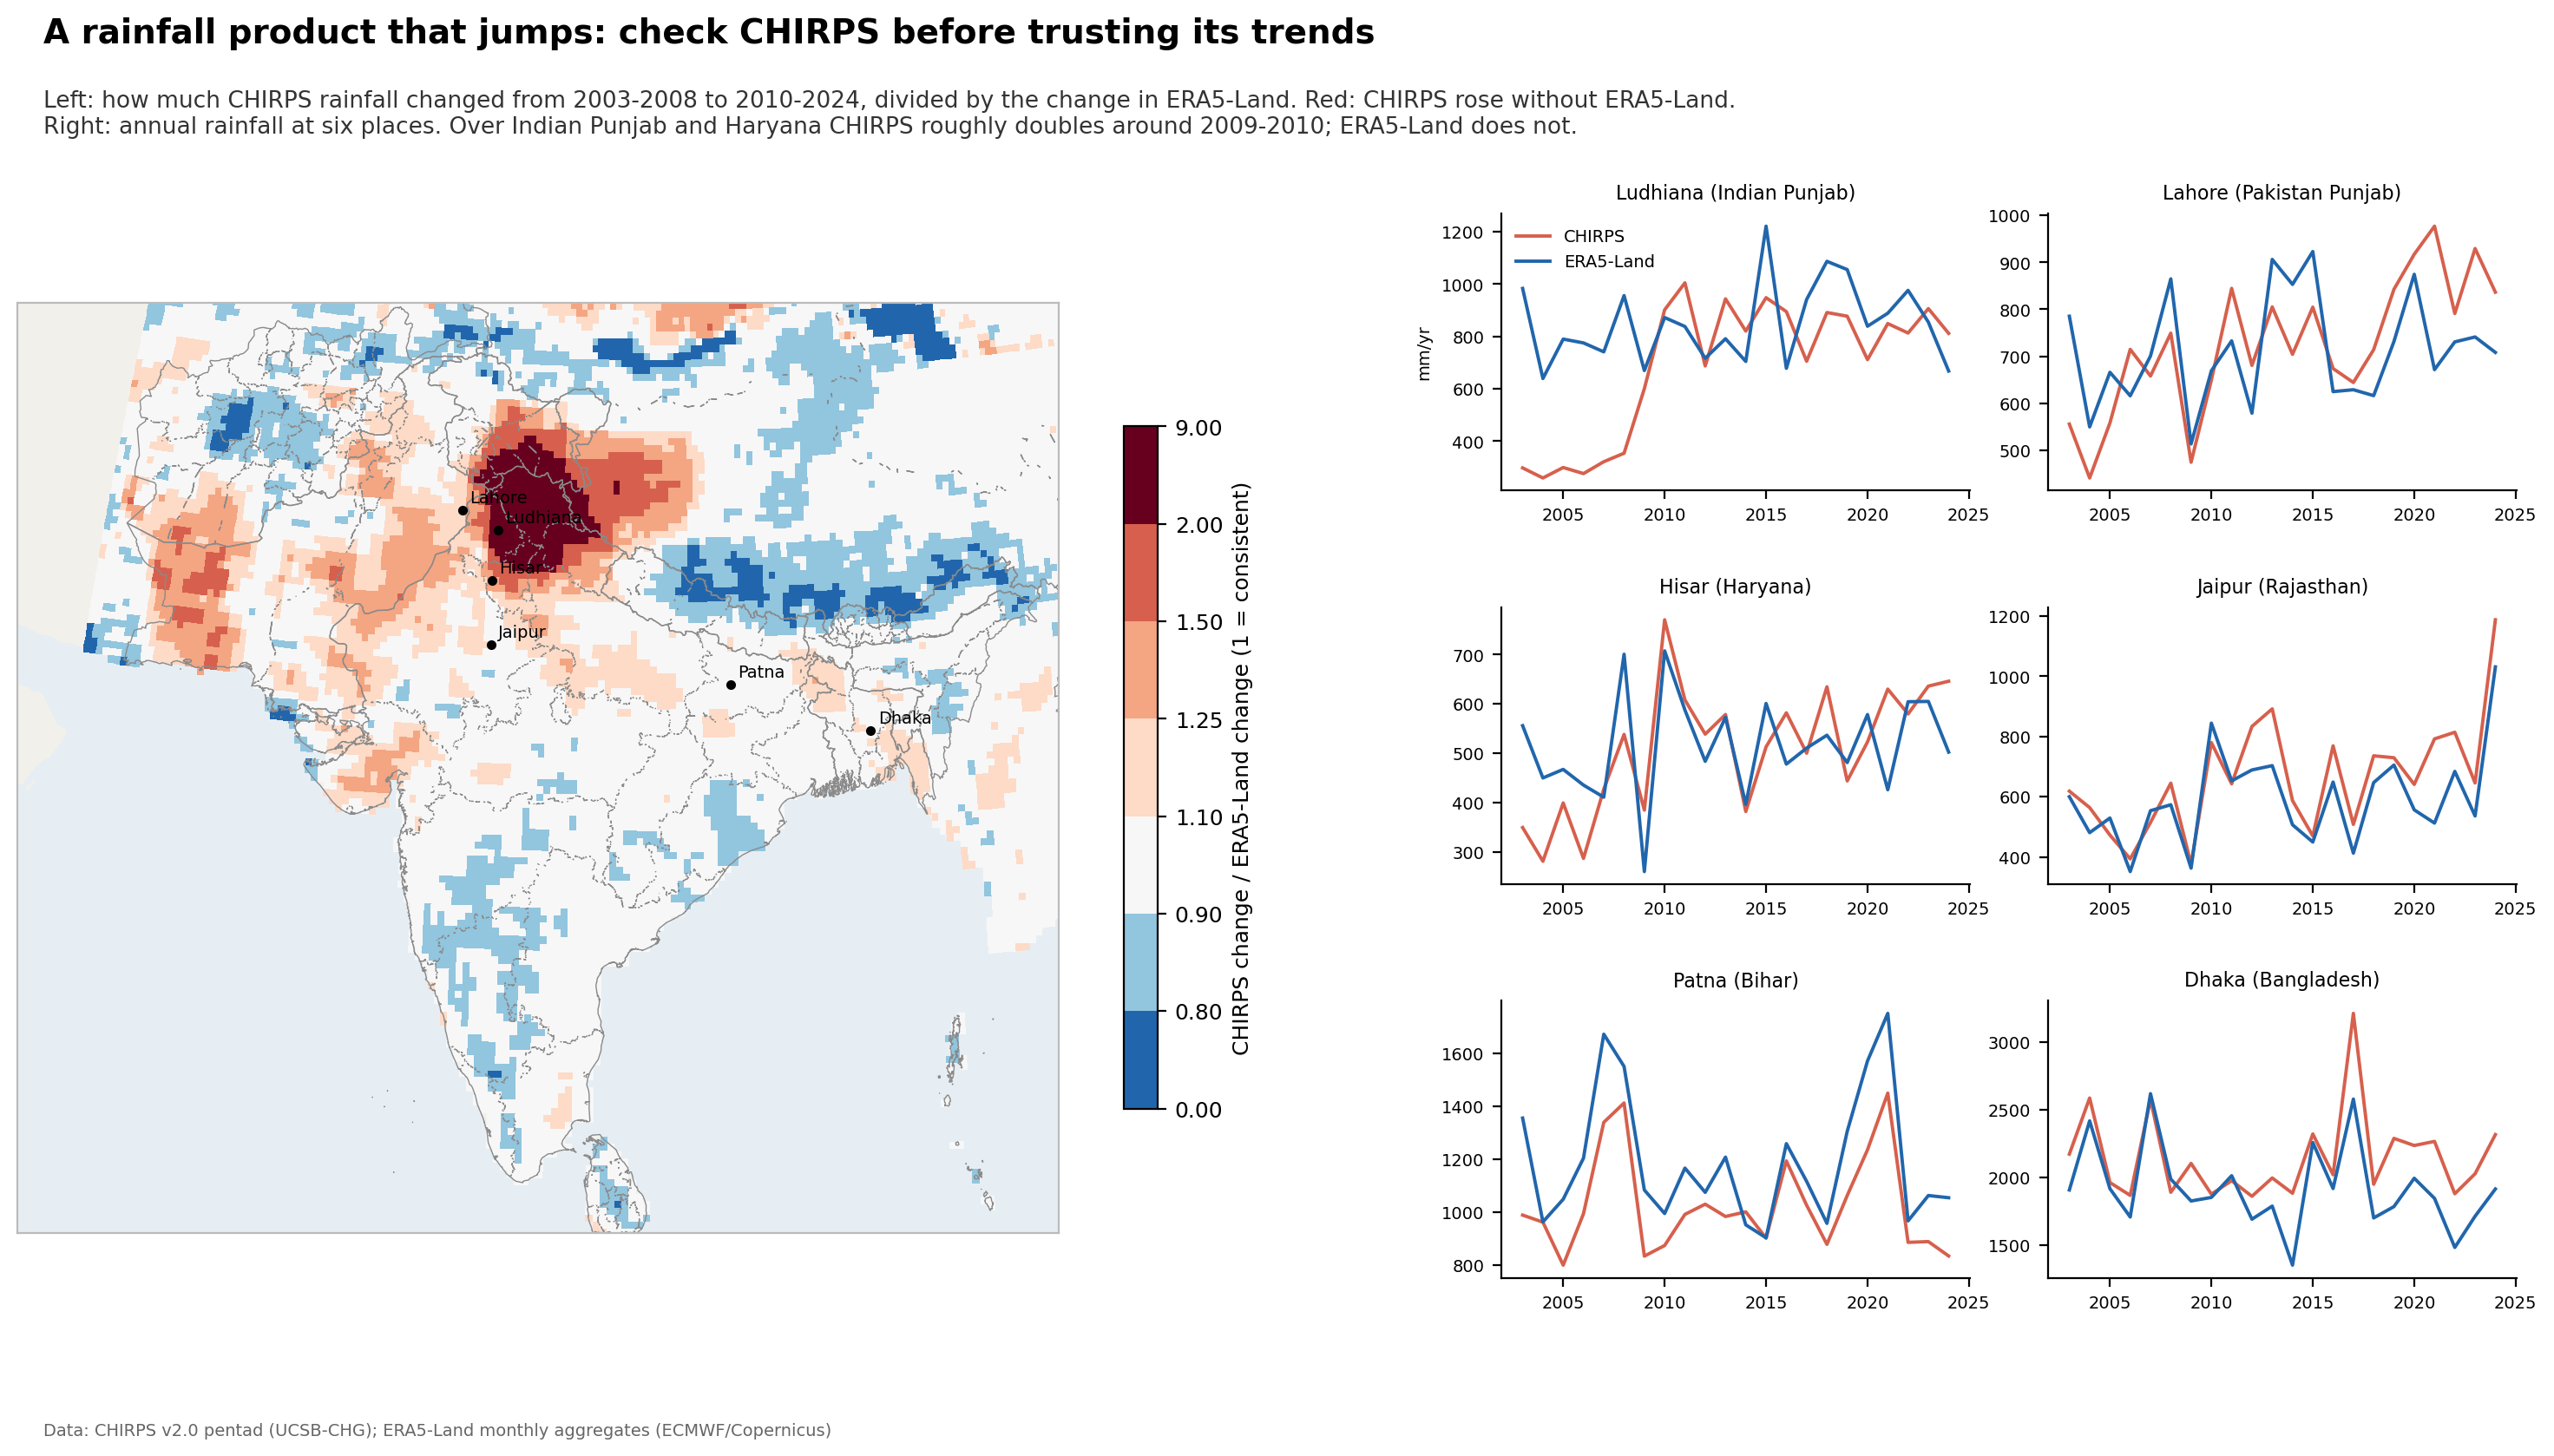

In [8]:
display(pd.read_csv(R / "outputs/chirps_check_points.csv").pivot_table(index="place", columns="product", values="mm",
        aggfunc=lambda s: s.iloc[7:].mean() / s.iloc[:6].mean()).round(2).rename_axis(None, axis=1),
        Image(M / "15_chirps_artefact.png", width=1000))

At Ludhiana, CHIRPS rainfall in 2010-2024 is 2.8 times that of 2003-2008; ERA5-Land's is 1.1 times. This was found
because a result looked wrong (rainfall "rising fastest" where groundwater falls fastest). The fix, ERA5-Land rainfall,
is in step 08, and the same correction was made in the commons-city livability layers for the Doab.